# 1 · Datos y partición temporal

MovieLens 25M: 25 millones de calificaciones (0,5 a 5 estrellas) de 162 mil usuarios sobre 59 mil películas, 1995 → 2019,
más el **Tag Genome** (relevancia de 1.128 etiquetas para 13.816 películas).

Preguntas de este notebook:
1. ¿Cómo son los datos (actividad en el tiempo, cola larga, señal implícita)?
2. ¿Por qué una **partición temporal global** y no aleatoria ni *leave-last-N* por usuario?
3. ¿Cuántos usuarios se pueden evaluar en cada segmento?

In [1]:
import json, sys
import numpy as np, pandas as pd
from IPython.display import Image, display
from recomendador import config as C
sys.path.insert(0, str(C.RAIZ))  # para importar api.main
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
from recomendador import datos
cal = datos.cargar_calificaciones()
print(f"{len(cal):,} calificaciones · {cal.userId.nunique():,} usuarios · {cal.movieId.nunique():,} películas")
print(f"Densidad: {len(cal) / (cal.userId.nunique() * cal.movieId.nunique()):.4%}")
cal["rating"].value_counts(normalize=True).sort_index().mul(100).round(1).rename("% de calificaciones").to_frame().T

25,000,095 calificaciones · 162,541 usuarios · 59,047 películas


Densidad: 0.2605%


rating,0.5000,1.0000,1.5000,2.0000,2.5000,3.0000,3.5000,4.0000,4.5000,5.0000
% de calificaciones,1.6000,3.1000,1.6000,6.6000,5.1000,19.6000,12.7000,26.6000,8.8000,14.4000


## Señal implícita: «le gustó» = 4 estrellas o más

Casi la mitad de las calificaciones son ≥ 4. Se trata como **positivo implícito** (lo vio y le gustó): es lo que la
mayoría de las plataformas tienen (reproducciones, compras), y es lo que se predice: *qué va a ver y disfrutar*,
no qué nota le pondría.

In [3]:
print(f"Positivos (≥ 4): {(cal.rating >= C.UMBRAL_POSITIVO).mean():.1%}")
por_usuario = cal.groupby("userId").size()
por_usuario.describe(percentiles=[.25, .5, .75, .9, .99]).round(0).to_frame("calificaciones por usuario").T

Positivos (≥ 4): 49.8%


,count,mean,std,min,25%,50%,75%,90%,99%,max
calificaciones por usuario,"162,541.0000",154.0000,268.0000,20.0000,36.0000,71.0000,162.0000,353.0000,"1,228.0000","32,202.0000"


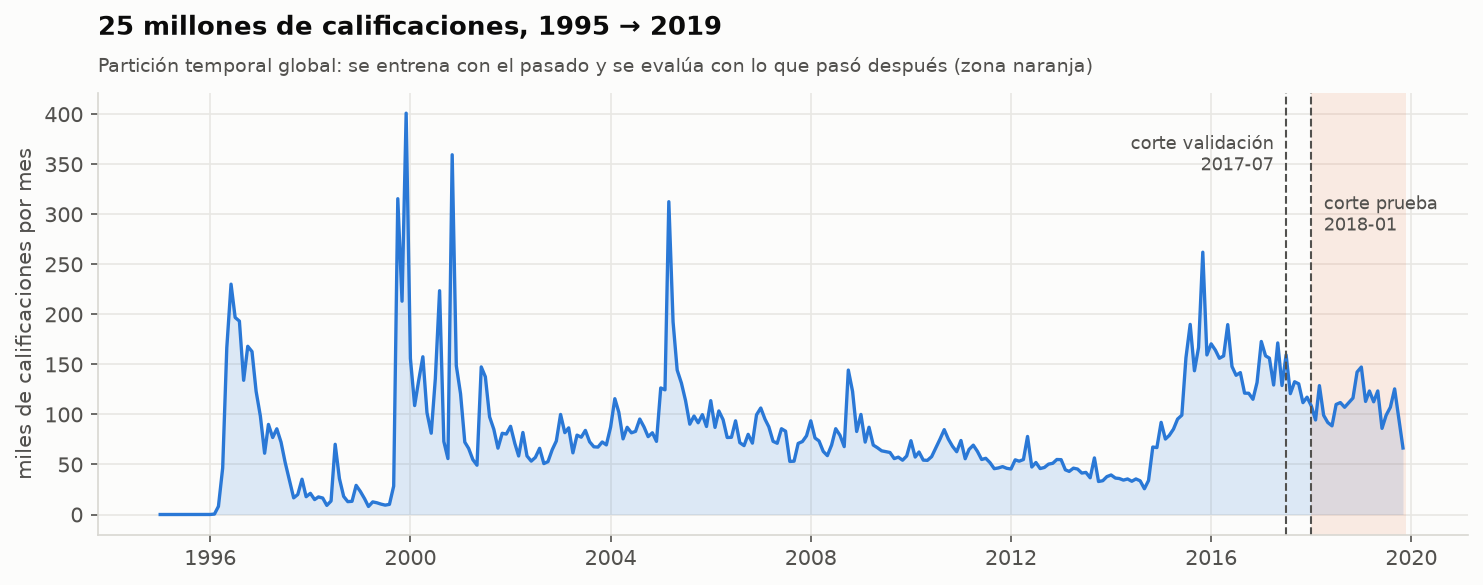

In [4]:
display(Image(str(C.FIGURAS / "01_actividad_y_cortes.png")))

## ¿Por qué la partición temporal GLOBAL?

Las particiones habituales filtran el futuro:

- **Aleatoria** (80/20 de las calificaciones): el modelo aprende de calificaciones de 2019 para «predecir» una de 2005.
- **Leave-last-N por usuario**: se esconde lo último de *cada* usuario, pero cada usuario tiene su propio reloj: lo
  último de un usuario de 2003 se predice con un modelo que vio todo lo que pasó hasta 2019 (qué películas se volvieron
  populares, qué estrenos existen).

Medimos cuánto futuro se cuela con *leave-last-one*: para la última calificación de cada usuario, ¿qué fracción del
entrenamiento ocurrió **después**?

In [5]:
ts = np.sort(cal["timestamp"].to_numpy())
ultimo = cal.groupby("userId")["timestamp"].max().to_numpy()
fraccion_futura = 1 - np.searchsorted(ts, ultimo, side="right") / len(ts)
print(f"Leave-last-one: en promedio el {fraccion_futura.mean():.1%} del entrenamiento es POSTERIOR al momento de prueba")
print(f"Para la mitad de los usuarios, más del {np.median(fraccion_futura):.1%} del entrenamiento es futuro")

Leave-last-one: en promedio el 53.8% del entrenamiento es POSTERIOR al momento de prueba
Para la mitad de los usuarios, más del 53.0% del entrenamiento es futuro


Con la **partición temporal global** todos los usuarios comparten el mismo reloj:

| | entrenamiento | evaluación | uso |
|---|---|---|---|
| validación | todo < 2017-07-01 | 2017-07 → 2017-12 | elegir hiperparámetros |
| prueba | todo < 2018-01-01 | 2018-01 → 2019-11 | se mira una vez |

- **Usuarios existentes**: tenían positivos antes del corte; se evalúa con lo que les gustó después (excluyendo lo ya visto).
- **Usuarios nuevos**: aparecen después del corte. Sus **5 primeras calificaciones** hacen de cuestionario de
  bienvenida (como el onboarding real de MovieLens) y se evalúa con el resto. Es el escenario de **arranque en frío**.
- **Catálogo recomendable**: películas con ≥ 5 positivos antes del corte.

In [6]:
hp = json.load(open(C.REPORTES / "hiperparametros.json", encoding="utf-8"))
res = json.load(open(C.REPORTES / "resultados.json", encoding="utf-8"))
pd.DataFrame({"validación": hp["particion"], "prueba": res["particion"]})

,validación,prueba
corte,2017-07-01,2018-01-01
fin,2018-01-01,2019-12-01
calificaciones_entrenamiento,21716191,22488700
positivos_entrenamiento,10808900,11182187
usuarios_entrenamiento,146859,150543
items_catalogo,16314,17102
calificaciones_ventana,772509,2511395
positivos_ventana,375891,1245580
usuarios_existentes_evaluables,3907,6267
usuarios_nuevos_evaluables,3557,11710


### ¿Por qué tan pocos usuarios existentes en la prueba?

De ~150 mil usuarios con historia, solo ~6 mil **vuelven** a calificar después de 2018. En MovieLens la mayoría de la
gente califica en una o dos sesiones y no regresa. Por eso la ventana de prueba es larga (23 meses): con 6 meses solo
volvían 271 usuarios con pocos positivos. Los usuarios que vuelven tienden a ser los más activos, y eso sesga los
segmentos hacia «muchos».

In [7]:
pu = pd.read_parquet(C.REPORTES / "metricas_por_usuario.parquet")
pu = pu[pu.modelo == "ALS implícito"]
tabla = pu.groupby("segmento").agg(usuarios=("usuario", "size"), positivos_mediana=("n_positivos", "median"),
                                   relevantes_mediana=("n_relevantes", "median"))
tabla.loc[["nuevos (onboarding)", "pocos (1-20)", "medios (21-100)", "muchos (>100)"]]

,usuarios,positivos_mediana,relevantes_mediana
segmento,,,
nuevos (onboarding),11710,4.0000,46.0000
pocos (1-20),479,13.0000,14.0000
medios (21-100),1977,57.0000,10.0000
muchos (>100),3811,226.0000,15.0000


## La cola larga

Pocas películas concentran casi todos los positivos. Un recomendador que solo recomienda éxitos parece «exacto» pero
no ayuda a descubrir nada. Por eso, además de NDCG, se miden **cobertura**, **novedad** y **sesgo de popularidad**
(notebook 3).

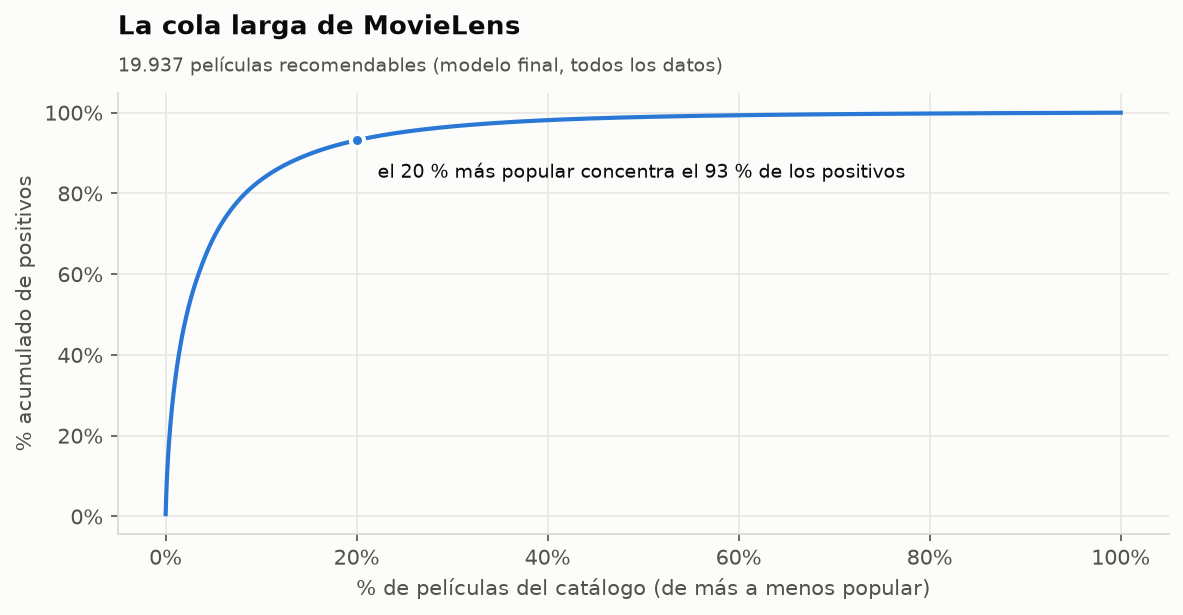

In [8]:
display(Image(str(C.FIGURAS / "06_cola_larga.png")))

## Tag Genome: el «ADN» de cada película

1.128 etiquetas con relevancia 0-1 calculada por GroupLens a partir de etiquetas, calificaciones y reseñas.
Es la base del modelo de contenido. **Ojo:** el genome se publicó en 2019 usando datos hasta 2019, así que contiene
algo de información del periodo de prueba (fuga leve, documentada en la ficha del modelo).

In [9]:
genome, etiquetas = datos.cargar_genome()
pel = datos.cargar_peliculas().set_index("movieId")
print(f"{genome.shape[0]:,} películas con genome · {genome.shape[1]:,} etiquetas")
for mid in [2571, 1, 4993]:
    top = genome.loc[mid].nlargest(8)
    print(f"{pel.loc[mid, 'titulo']}: " + ", ".join(f"{etiquetas[t - 1]} ({v:.2f})" for t, v in top.items()))

13,816 películas con genome · 1,128 etiquetas
Matrix, The (1999): dystopic future (1.00), scifi (0.99), cyberpunk (0.99), sci fi (0.99), science fiction (0.99), dark hero (0.99), special effects (0.98), technology (0.98)
Toy Story (1995): toys (1.00), computer animation (1.00), pixar animation (1.00), kids and family (0.99), animation (0.98), kids (0.98), pixar (0.96), children (0.96)
Lord of the Rings: The Fellowship of the Ring, The (2001): high fantasy (1.00), liv tyler (1.00), scenic (0.99), wizards (0.99), trilogy (0.99), fantasy world (0.99), mythology (0.99), modern fantasy (0.99)
